In [2]:
%pip install --upgrade --force-reinstall numpy==2.2.6 scipy==1.15.3 scikit-learn==1.6.1

  Using cached numpy-2.2.6-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
  Using cached scipy-1.15.3-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached scikit_learn-1.6.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (18 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached numpy-2.2.6-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.5 MB)
Using cached scipy-1.15.3-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (37.3 MB)
Using cached scikit_learn-1.6.1-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (13.1 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached threadpoolctl-3.8.0-py3-none-any.whl (32 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
  Attempting uninstall: thr

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import requests
import zipfile
import io
import os
import joblib
import warnings

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

response = requests.get(url)
response.raise_for_status()

outer_zip = zipfile.ZipFile(io.BytesIO(response.content))

print("Files inside downloaded ZIP:")
print(outer_zip.namelist())

# Extract inner bank.zip
inner_zip_bytes = outer_zip.read("bank.zip")
inner_zip = zipfile.ZipFile(io.BytesIO(inner_zip_bytes))

# Find bank-full.csv
csv_file = next(
    name for name in inner_zip.namelist()
    if name.endswith("bank-full.csv")
)

# Load dataset
df = pd.read_csv(
    inner_zip.open(csv_file),
    sep=";"
)

print("\nDataset downloaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Files inside downloaded ZIP:
['bank.zip', 'bank-additional.zip']

Dataset downloaded successfully!
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

print("\nTarget distribution:")
print(df["y"].value_counts())

print("\nTarget distribution in percentage:")
print(df["y"].value_counts(normalize=True) * 100)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Missing values in each column:
age          0
job          0
marital      0
e

In [6]:
X = df.drop(columns=["y", "duration"])
y = df["y"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Input features shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nNumerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

Input features shape: (45211, 15)
Target variable shape: (45211,)

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Number of numerical features: 6
Number of categorical features: 9


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    sparse_threshold=0
)

print("Preprocessing configuration created successfully!")

Preprocessing configuration created successfully!


In [8]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        kernel="rbf",
        probability=False, cache_size=1000,
        random_state=42
    )
}

print("All five classification models defined successfully!")

All five classification models defined successfully!


In [11]:
print("X exists:", "X" in globals())
print("y exists:", "y" in globals())
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())
print("preprocessor exists:", "preprocessor" in globals())
print("df exists:", "df" in globals())

X exists: True
y exists: True
X_train exists: False
y_train exists: False
preprocessor exists: True
df exists: True


In [13]:
# Recreate training and testing variables

X = df.drop("y", axis=1)
y = df["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training and testing data created!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

Training and testing data created!
X_train: (36168, 16)
X_test: (9043, 16)


In [15]:
results = []
trained_models = {}

os.makedirs("models", exist_ok=True)

for model_name, classifier in models.items():

    print("\nTraining", model_name, "...")

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    fitted_classifier = pipeline.named_steps["classifier"]

    if hasattr(fitted_classifier, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

    y_true_binary = (y_test == "yes").astype(int)

    results.append({
        "ML Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_true_binary, y_score),
        "Precision": precision_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label="yes", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

    trained_models[model_name] = pipeline

    filename = model_name.lower().replace(" ", "_")

    joblib.dump(pipeline, f"models/{filename}.joblib")

    print(model_name, "trained successfully!")

print("\nAll five models trained successfully!")


Training Logistic Regression ...
Logistic Regression trained successfully!

Training Decision Tree ...
Decision Tree trained successfully!

Training KNN ...
KNN trained successfully!

Training Naive Bayes ...
Naive Bayes trained successfully!

Training Support Vector Machine ...
Support Vector Machine trained successfully!

All five models trained successfully!


In [17]:
comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

comparison_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")

,ML Model Name,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8933,0.7717,0.6632,0.1786,0.2815,0.3065
1,Decision Tree,0.8309,0.6132,0.2982,0.3289,0.3128,0.2170
2,KNN,0.8874,0.7027,0.5529,0.1975,0.2911,0.2833
3,Naive Bayes,0.8452,0.7514,0.3708,0.4641,0.4123,0.3271
4,Support Vector Machine,0.8933,0.7184,0.6555,0.1853,0.2889,0.3098


Comparison table saved successfully!


In [19]:
print("Saved model files:")

for filename in sorted(os.listdir("models")):
    print(filename)

print("\nTotal models saved:", len(os.listdir("models")))

Saved model files:
decision_tree.joblib
knn.joblib
logistic_regression.joblib
naive_bayes.joblib
support_vector_machine.joblib

Total models saved: 5


In [21]:
best_model = comparison_df.iloc[0]

print("Best model based on F1 Score:")
print(best_model["ML Model Name"])

print("\nF1 Score:", round(best_model["F1 Score"], 4))
print("MCC Score:", round(best_model["MCC"], 4))
print("AUC Score:", round(best_model["AUC"], 4))

Best model based on F1 Score:
Logistic Regression

F1 Score: 0.2815
MCC Score: 0.3065
AUC Score: 0.7717


Classification Report:
              precision    recall  f1-score   support

          no       0.90      0.99      0.94      7985
         yes       0.66      0.18      0.28      1058

    accuracy                           0.89      9043
   macro avg       0.78      0.58      0.61      9043
weighted avg       0.87      0.89      0.87      9043



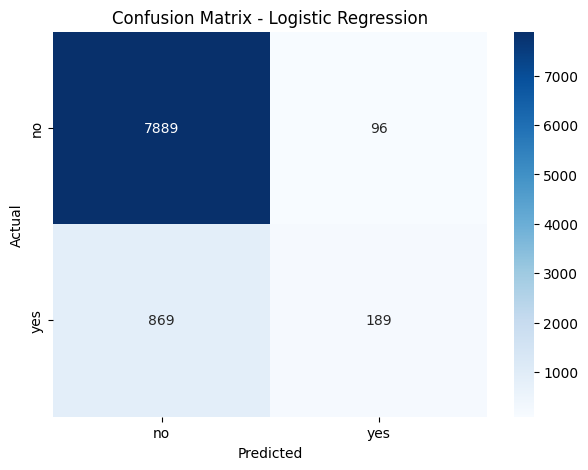

In [23]:
best_name = best_model["ML Model Name"]

best_pipeline = trained_models[best_name]

y_pred = best_pipeline.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["no", "yes"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["no", "yes"],
    yticklabels=["no", "yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_name)

plt.show()

In [25]:
test_data = X_test.copy()

test_data["y"] = y_test

test_data.to_csv(
    "test_data.csv",
    index=False
)

print("Test data saved successfully!")
print("Test data shape:", test_data.shape)

Test data saved successfully!
Test data shape: (9043, 17)


In [27]:
print("Saved model files:")

for filename in os.listdir("models"):
    print(filename)

print("\nModel count:", len(os.listdir("models")))

print("\nOther saved files:")
print("test_data.csv:", os.path.exists("test_data.csv"))
print("model_comparison.csv:", os.path.exists("model_comparison.csv"))

Saved model files:
naive_bayes.joblib
logistic_regression.joblib
decision_tree.joblib
support_vector_machine.joblib
knn.joblib

Model count: 5

Other saved files:
test_data.csv: True
model_comparison.csv: True


In [29]:
import shutil

shutil.make_archive(
    "ML_Assignment_2_Artifacts",
    "zip",
    ".",
    "models"
)

with zipfile.ZipFile(
    "ML_Assignment_2_Artifacts.zip",
    "a"
) as zip_file:

    zip_file.write(
        "test_data.csv",
        "test_data.csv"
    )

    zip_file.write(
        "model_comparison.csv",
        "model_comparison.csv"
    )

print("All assignment artifacts packaged successfully!")

All assignment artifacts packaged successfully!


In [1]:
import os

print("Current directory:")
print(os.getcwd())

print("\nFiles in current directory:")
print(os.listdir("."))

Current directory:
/home/s2026aj05895/workspace/dms

Files in current directory:
['models', '.ipynb_checkpoints', 'Untitled.ipynb', 'model_comparison.csv', 'test_data.csv', 'ML_Assignment_2_Artifacts.zip', 'ML2.ipynb']
